# Ecuaciones de Lotka-Volterra:  presa-depredador.

### Las ecuaciones de Lotka-Volterra son un modelo biomatemático que pretende responder a estas cuestiones prediciendo la dinámica de las poblaciones de presa y depredador bajo una serie de hipótesis:

- El ecosistema está aislado: no hay migración, no hay otras especies presentes, no hay plagas...
- La población de presas en ausencia de depredadores crece de manera exponencial: la velocidad de reproducción es proporcional al número de individuos. Las presas sólo mueren cuando son cazadas por el depredador.
- La población de depredadores en ausencia de presas decrece de manera exponencial.
- La población de depredadores afecta a la de presas haciéndola decrecer de forma proporcional al número de presas y depredadores (proporcional al número de encuentros presa y depredador).
- La población de presas afecta a la de depredadores de manera proporcional al número de encuentros, pero con distinta constante de proporcionalidad (dependerá de cuanto sacien su hambre los depredadores al encontrar una presa).



### Se modelizan mediante un sistema de dos ecuaciones diferenciales de primer orden, acopladas, autónomas y no lineales:

$$ \frac{dx}{dt} = \alpha x - \beta x y $$$$ \frac{dy}{dt} = -\gamma y + \delta y x $$
$x$ es el número de presas, $y$ es el número de depredadores. Los parámetros son constantes positivas que representan:
- $\alpha$: tasa de crecimiento de las presas.
- $\beta$: éxito en la caza del depredador.
- $\gamma$: tasa de decrecimiento de los depredadores.
- $\delta$: éxito en la caza y cuánto alimenta cazar una presa al depredador.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import odeint

In [2]:
def df_dt(x, t, a, b, c, d):
    
    dx = a * x[0] - b * x[0] * x[1]
    dy = - c * x[1] + d * x[0] * x[1]
    
    return np.array([dx, dy])

In [3]:
def df_dt(x, t, a, b, c, d):
    sol = [a * x[0] - b * x[0] * x[1],
          - c * x[1] + d * x[0] * x[1]]
    return sol

In [4]:
# CONSTANTES ECUACUACIONES
a = 0.1
b = 0.02
c = 0.3
d = 0.01

In [5]:
# CONDICIONES INICIALES
x0 = 40
y0 = 9
conds_iniciales = np.array([x0, y0])

In [6]:
# INTEGRACION
tf = 200
N = 800
t = np.linspace(0, tf, N)

In [7]:
# RESOLVEMOS ECUACIONES
solucion = odeint(df_dt, conds_iniciales, t, args=(a, b, c, d))

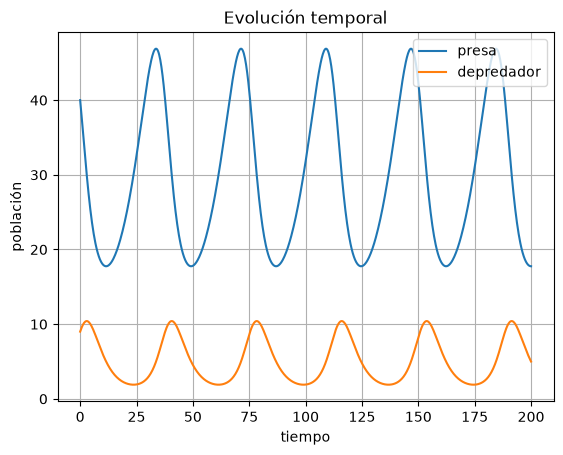

In [12]:
# FIGURA EVOLUCION TEMPORAL
plt.figure("Evolución temporal")
plt.title("Evolución temporal")
plt.plot(t, solucion[:, 0], label='presa')
plt.plot(t, solucion[:, 1], label='depredador')
plt.xlabel('tiempo')
plt.ylabel('población')
plt.xlim((-10,210))
plt.grid(True)
plt.legend(loc=1)
plt.show()


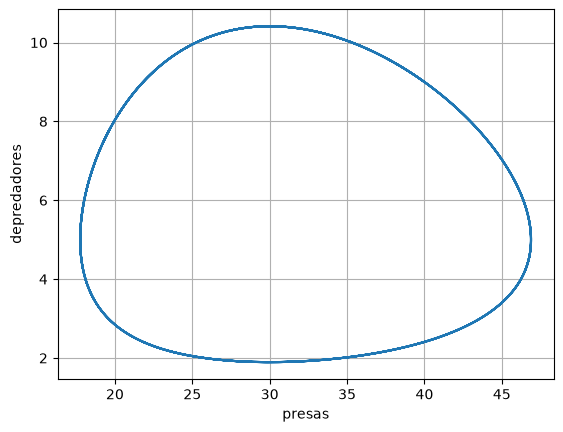

In [13]:
# MAPA DE FASES: PRESAS vs DEPREDADORES
plt.figure("Presas vs depredadores")
plt.grid(True)
plt.plot(solucion[:, 0], solucion[:, 1])
plt.xlabel('presas')
plt.ylabel('depredadores')
plt.show()

### RESULTADO: SOLUCION PERIODICA

C:\Users\sebas\AppData\Local\Temp\ipykernel_17372\3905408625.py:10: RuntimeWarning: invalid value encountered in divide
  uu = uu / norm
C:\Users\sebas\AppData\Local\Temp\ipykernel_17372\3905408625.py:11: RuntimeWarning: invalid value encountered in divide
  vv = vv / norm


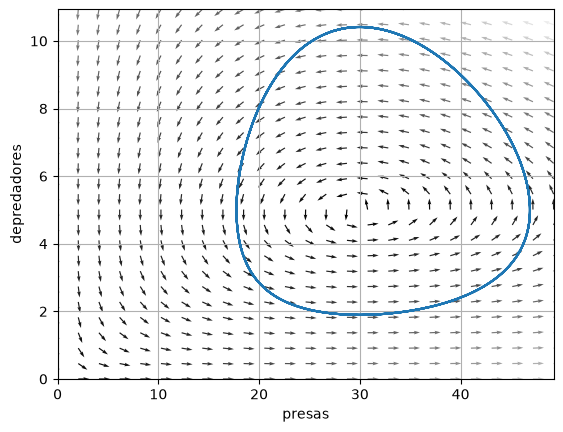

In [19]:
x_max = np.max(solucion[:,0]) * 1.05
y_max = np.max(solucion[:,1]) * 1.05

x = np.linspace(0, x_max, 25)
y = np.linspace(0, y_max, 25)

xx, yy = np.meshgrid(x, y)
uu, vv = df_dt((xx, yy), 0, a, b, c, d)
norm = np.sqrt(uu**2 + vv**2)
uu = uu / norm
vv = vv / norm

plt.figure("Campo de direcciones")
plt.grid(True)
plt.quiver(xx, yy, uu, vv, norm, cmap=plt.cm.gray)
plt.plot(solucion[:, 0], solucion[:, 1])
plt.xlim(0, x_max)
plt.ylim(0, y_max)
plt.xlabel('presas')
plt.ylabel('depredadores')
plt.show()

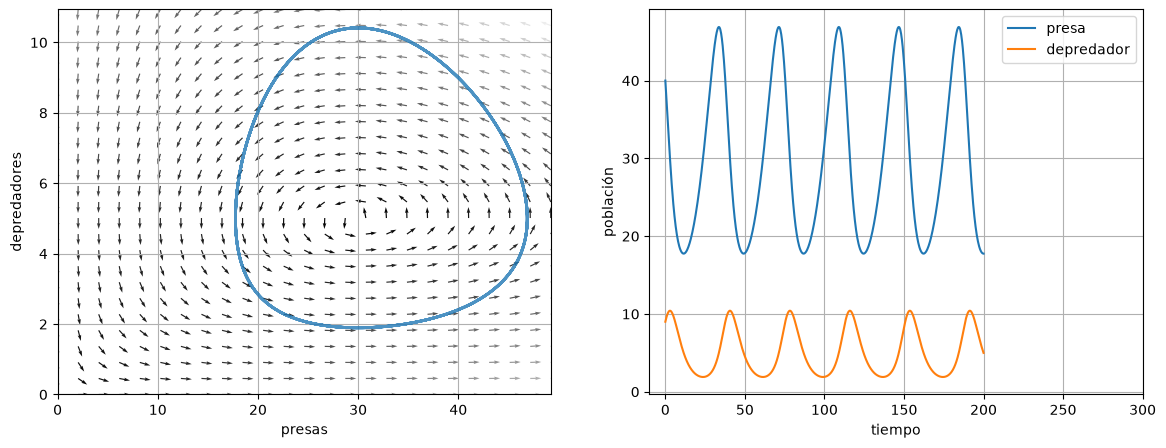

In [21]:
#n_max = np.max(solucion) * 1.10

fig, ax = plt.subplots(1,2, figsize=(14, 5))

ax[0].grid(True)
ax[0].quiver(xx, yy, uu, vv, norm, cmap=plt.cm.gray)
ax[0].plot(solucion[:, 0], solucion[:, 1], lw=2, alpha=0.8)
ax[0].set_xlim(0, x_max)
ax[0].set_ylim(0, y_max)
ax[0].set_xlabel('presas')
ax[0].set_ylabel('depredadores')

ax[1].grid(True)
ax[1].plot(t, solucion[:, 0], label='presa')
ax[1].plot(t, solucion[:, 1], label='depredador')
ax[1].legend(loc=1)
ax[1].set_xlim((-10,300))
ax[1].set_xlabel('tiempo')
ax[1].set_ylabel('población')
plt.show()

### Que pasaría si el número inicial de presas y depredadores cambia

Se puede demostrar que a lo largo de la linea del espacio de fases, la cantidad :
    $$ C = \alpha \ln{y} - \beta y + \gamma \ln{x} -\delta x $$
se conserva.

Luego, pintando un contour de esta cantidad se obtiene la solución para distintos valores iniciales  del problema.
    

In [22]:
def C(x, y, a, b, c, d):
    return a * np.log(y) - b * y + c * np.log(x) - d * x

C:\Users\sebas\AppData\Local\Temp\ipykernel_17372\1105392651.py:2: RuntimeWarning: divide by zero encountered in log
  return a * np.log(y) - b * y + c * np.log(x) - d * x


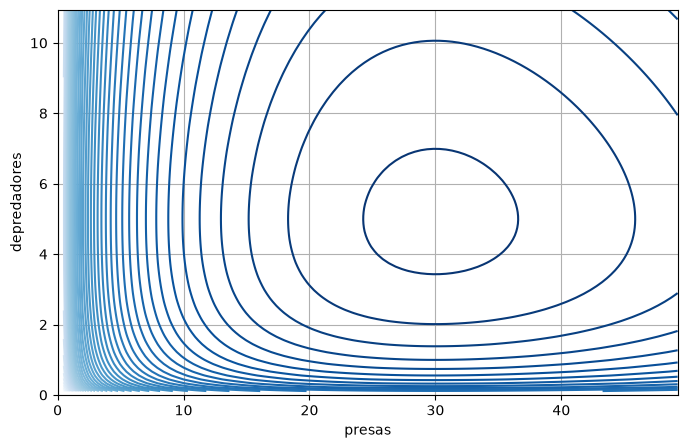

In [24]:
x = np.linspace(0, x_max, 100)
y = np.linspace(0, y_max, 100)
xx, yy = np.meshgrid(x, y)
constant = C(xx, yy, a, b, c, d)

plt.figure('distintas_soluciones', figsize=(8,5))
plt.contour(xx, yy, constant, 50, cmap=plt.cm.Blues)
plt.xlabel('presas')
plt.grid(True)
plt.ylabel('depredadores')
plt.show()

Vemos que estas curvas se van haciendo cada vez más y más pequeñas hasta colapsar en un punto en torno a $(30,5)$. 
Se trata de un punto de equilibrio o punto crítico; si el sistema lo alcanzase, no evolucionaría y el número de presas y depredadores sería constante en el tiempo. 
El otro punto crítico de nuestro sistema es el $(0,0)$. 
Analizándolos matemáticamente se obtiene que:
El punto crítico situado en $(0,0)$ es un punto de silla. Al tratarse de un punto de equilibrio inestable la extinción de cualquiera de las dos especies en el modelo sólo puede conseguirse imponiendo la condición inicial nula. El punto crítico situado en $(γ/δ,α/β)$ es un centro.

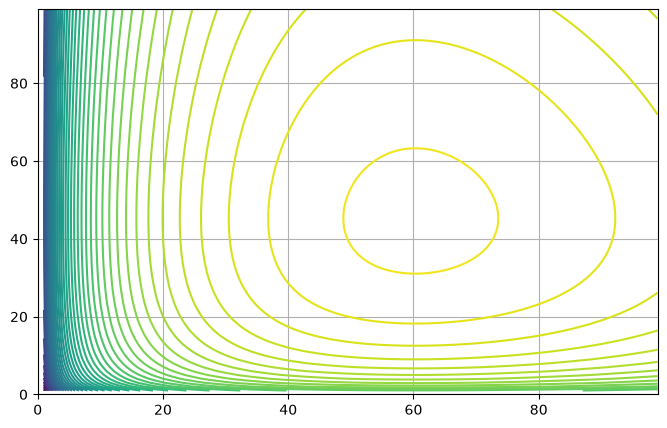

In [25]:
plt.figure('distintas_soluciones', figsize=(8,5))
plt.contour(constant, 50)
plt.grid(True)
plt.show()


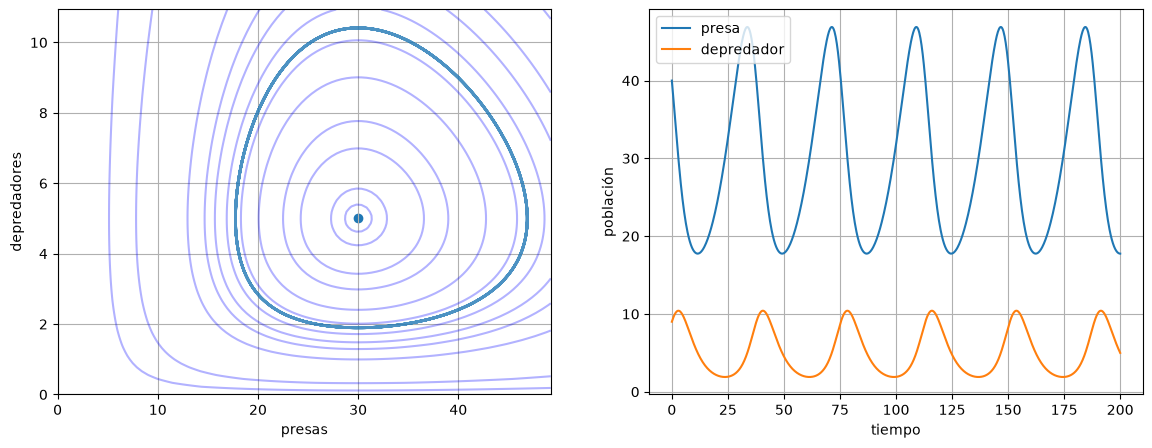

In [26]:
fig, ax = plt.subplots(1,2, figsize=(14, 5))

ax[0].plot(solucion[:, 0], solucion[:, 1], lw=2, alpha=0.8)
ax[0].scatter(c/d, a/b)
levels = (0.5, 0.6, 0.7, 0.72, 0.73, 0.74, 0.75, 0.76, 0.77, 0.775, 0.78, 0.781)
ax[0].contour(xx, yy, constant, levels, colors='blue', alpha=0.3)
ax[0].set_xlim(0, x_max)
ax[0].set_ylim(0, y_max)
ax[0].set_xlabel('presas')
ax[0].set_ylabel('depredadores')
ax[0].grid(True)

ax[1].grid(True)
ax[1].plot(t, solucion[:, 0], label='presa')
ax[1].plot(t, solucion[:, 1], label='depredador')
ax[1].legend()
ax[1].set_xlabel('tiempo')
ax[1].set_ylabel('población')
plt.show()



### MEJORAS DEL MODELO

Este modelo es demasiado simple debido a las hipótesis iniciales. Una mejora razonable seria modificar el modelo de crecimiento de las presas en ausencia de depredadores, suponiendo que en vez de aumentar de forma exponencial, lo hacen según una función logística. 


Esta curva crece de forma similar a una exponencial al principio, moderándose después y estabilizándose asintóticamente en un valor:

In [28]:
def logistic_curve(t, a, m, n, tau):
    e = np.exp(-t / tau)
    return a * (1 + m * e) / (1 + n * e)

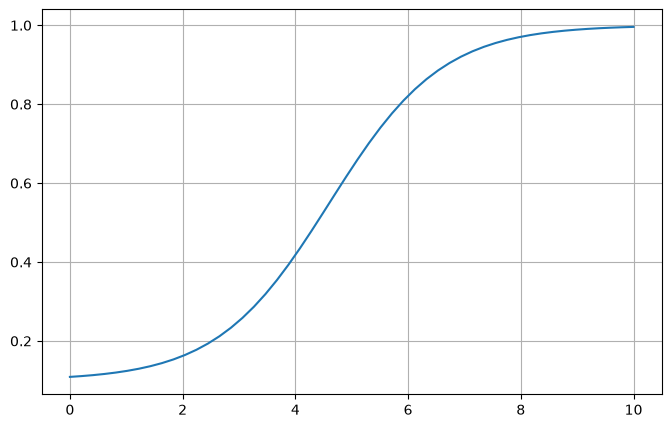

In [31]:
x = np.linspace(0,10)
plt.figure('función logística', figsize=(8,5))
plt.plot(x, logistic_curve(x, 1, m=10, n=100, tau=1))
plt.grid(True)
plt.show()

Este modelo de crecimiento representa mejor las limitaciones en el número de presas debidas al medio (falta de alimento, territorio...). Llevando este modelo de crecimiento a las ecuaciones originales se tiene un nuevo sistema en el que interviene un parámetro más:


$$ \frac{dx}{dt} = \left(\alpha x - rx^2\right)-\beta x y $$ $$ \frac{dy}{dt} = -\gamma y + \delta y x $$

In [33]:
def df_dt_logistic(x, t, a, b, c, d, r):
    
    dx = a * x[0] - r * x[0]**2 - b * x[0] * x[1]
    dy = - c * x[1] + d * x[0] * x[1]
    
    return np.array([dx, dy])

In [34]:
# CONSTANTES ECUACUACIONES
a = 0.1
b = 0.02
c = 0.3
d = 0.01
r = 0.001

In [35]:
# CONDICIONES INICIALES
x0 = 40
y0 = 9
conds_iniciales = np.array([x0, y0])

In [36]:
# INTEGRACION
tf = 200
N = 800
t = np.linspace(0, tf, N)

In [37]:
solucion_logistic = odeint(df_dt_logistic, conds_iniciales, t, args=(a, b, c, d, r))

C:\Users\sebas\AppData\Local\Temp\ipykernel_17372\2618340398.py:14: RuntimeWarning: invalid value encountered in divide
  uu = uu / norm
C:\Users\sebas\AppData\Local\Temp\ipykernel_17372\2618340398.py:15: RuntimeWarning: invalid value encountered in divide
  vv = vv / norm


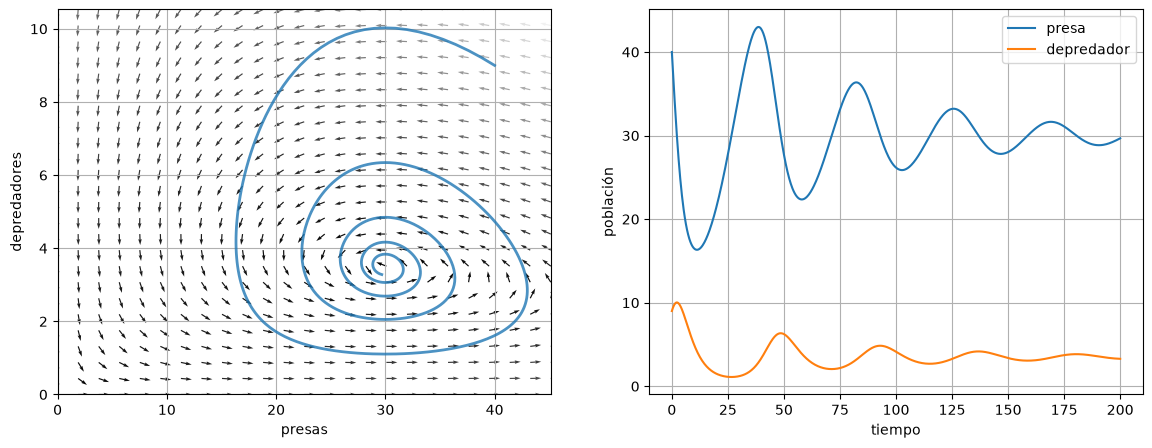

In [40]:
n_max = np.max(solucion) * 1.10

fig, ax = plt.subplots(1,2, figsize=(14, 5))

x_max = np.max(solucion_logistic[:,0]) * 1.05
y_max = np.max(solucion_logistic[:,1]) * 1.05

x = np.linspace(0, x_max, 25)
y = np.linspace(0, y_max, 25)

xx, yy = np.meshgrid(x, y)
uu, vv = df_dt_logistic((xx, yy), 0, a, b, c, d, r)
norm = np.sqrt(uu**2 + vv**2)
uu = uu / norm
vv = vv / norm

ax[0].quiver(xx, yy, uu, vv, norm, cmap=plt.cm.gray)
ax[0].plot(solucion_logistic[:, 0], solucion_logistic[:, 1], lw=2, alpha=0.8)
ax[0].set_xlim(0, x_max)
ax[0].set_ylim(0, y_max)
ax[0].set_xlabel('presas')
ax[0].set_ylabel('depredadores')
ax[0].grid(True)

ax[1].grid(True)
ax[1].plot(t, solucion_logistic[:, 0], label='presa')
ax[1].plot(t, solucion_logistic[:, 1], label='depredador')
ax[1].legend()
ax[1].set_xlabel('tiempo')
ax[1].set_ylabel('población')
plt.show()

En este caso se puede observar como el comportamiento deja de ser periódico. El punto crítico que antes era un centro, se convierte en un atractor y la solución tiende a estabilizarse en un número fijo de presas y depredadores.


In [42]:
from ipywidgets.widgets import interact

In [43]:
def solucion_temporal_interact(a, b, c, d, x0, y0, tf):
    
    conds_iniciales = np.array([x0, y0])

    # Condiciones para integración
    N = 800
    t = np.linspace(0, tf, N)
    
    solucion = odeint(df_dt, conds_iniciales, t, args=(a, b, c, d))
    
    plt.figure("Evolución temporal", figsize=(8,5))
    plt.title("Evolución temporal")
    plt.plot(t, solucion[:, 0], label='presa')
    plt.plot(t, solucion[:, 1], label='depredador')
    plt.xlabel('tiempo')
    plt.ylabel('población')
    plt.legend()
    plt.show()

In [ ]:
interact(solucion_temporal_interact,
         a=(0.01,0.5), b=(0.01,0.5),
         c=(0.01,0.5), d=(0.01,0.5),
         x0=(1,80), y0=(1,50),
         tf=(50,300));

interactive(children=(FloatSlider(value=0.255, description='a', max=0.5, min=0.01), FloatSlider(value=0.255, d…

In [45]:
def mapa_fases_interact(a, b, c, d, x0, y0, tf):
    
    conds_iniciales = np.array([x0, y0])

    # Condiciones para integración
    N = 800
    t = np.linspace(0, tf, N)
    
    solucion = odeint(df_dt, conds_iniciales, t, args=(a, b, c, d))
    
    x_max = np.max(solucion[:,0]) * 1.05
    y_max = np.max(solucion[:,1]) * 1.05

    x = np.linspace(0, x_max, 25)
    y = np.linspace(0, y_max, 25)

    xx, yy = np.meshgrid(x, y)
    uu, vv = df_dt((xx, yy), 0, a, b, c, d)
    norm = np.sqrt(uu**2 + vv**2)
    uu = uu / norm
    vv = vv / norm

    plt.figure("Campo de direcciones", figsize=(8,5))
    plt.quiver(xx, yy, uu, vv, norm, cmap=plt.cm.gray)
    plt.plot(solucion[:, 0], solucion[:, 1])
    plt.xlim(0, x_max)
    plt.ylim(0, y_max)
    plt.xlabel('presas')
    plt.ylabel('depredadores')
    plt.show()

In [46]:
interact(mapa_fases_interact,
         a=(0.01,0.5), b=(0.01,0.5),
         c=(0.01,0.5), d=(0.01,0.5),
         x0=(1,80), y0=(1,50),
         tf=(50,300));

interactive(children=(FloatSlider(value=0.255, description='a', max=0.5, min=0.01), FloatSlider(value=0.255, d…